# King County 房价预测：端到端机器学习项目

**课程对应：** 《Hands-On Machine Learning》第 2 章 End-to-End Machine Learning Project  
**数据集：** King County House Sales  
**目标变量：** `price`（美元）


## 环节 1：数据获取与加载

**这一步在做什么：** 定义数据加载函数，读取 `kc_house_data.csv` 并查看样本规模。  
**为什么要做：** 统一数据入口，确认文件、样本数和字段数正确，方便后续复现。  
**如何被纳入 Pipeline：** 本环节只负责得到原始 DataFrame；Pipeline 从后续预处理阶段开始，原始数据不会提前手工变换。


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


RANDOM_STATE = 42
DATA_PATH = Path("kc_house_data.csv")

def load_kingcounty_data(path=DATA_PATH):
    """加载 King County 房屋销售数据。"""
    if not path.is_file():
        raise FileNotFoundError(f"找不到数据文件：{path.resolve()}")
    return pd.read_csv(path)

housing = load_kingcounty_data()
print(f"数据形状：{housing.shape}")
display(housing.head())


数据形状：(21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 环节 2：数据初探

**这一步在做什么：** 查看字段类型、描述性统计和缺失值，并检查离散字段的频数。  
**为什么要做：** 确认哪些列是数值特征、哪些列应按类别处理，同时发现异常值线索，例如 bedrooms 的极端记录。  
**如何被纳入 Pipeline：** 本环节只做探索，不对全量数据 `fit` 任何预处理器；真正的填补、编码和缩放在环节 5–8 的 Pipeline 中完成。


In [2]:
# 查看数据类型、字段数量和内存占用
housing.info()

# 查看数值字段的统计量，初步识别量纲和极端值
display(housing.describe().T)

# 检查缺失值，为环节 5 的 SimpleImputer 策略提供依据
missing = housing.isna().sum().sort_values(ascending=False)
display(missing.to_frame("missing_count"))

# 检查离散字段的取值分布
for column in ["bedrooms", "waterfront", "view", "condition", "grade", "zipcode"]:
    print(f"\n{column} 的频数：")
    display(housing[column].value_counts().sort_index().head(20))

# 目标变量和关键字段的范围
display(housing[["price", "sqft_living", "yr_built", "yr_renovated"]].describe().T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.409430e+00,6.507430e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


,missing_count
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0



bedrooms 的频数：


bedrooms
0       13
1      199
2     2760
3     9824
4     6882
5     1601
6      272
7       38
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64

...


grade 的频数：


grade
1        1
3        3
4       29
5      242
6     2038
7     8981
8     6068
9     2615
10    1134
11     399
12      90
13      13
Name: count, dtype: int64


zipcode 的频数：


zipcode
98001    362
98002    199
98003    280
98004    317
98005    168
98006    498
98007    141
98008    283
98010    100
98011    195
98014    124
98019    190
98022    234
98023    499
98024     81
98027    412
98028    283
98029    321
98030    256
98031    274
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
price,21613.0,540088.141767,367127.196483,75000.0,321950.0,450000.0,645000.0,7700000.0
sqft_living,21613.0,2079.899736,918.440897,290.0,1427.0,1910.0,2550.0,13540.0
yr_built,21613.0,1971.005136,29.373411,1900.0,1951.0,1975.0,1997.0,2015.0
yr_renovated,21613.0,84.402258,401.679240,0.0,0.0,0.0,0.0,2015.0


## 环节 3：可视化探索

**这一步在做什么：** 绘制价格分布、对数价格分布、数值相关性热图和地理散点图。  
**为什么要做：** 观察目标变量是否右偏，发现与价格相关的变量，并检查 Seattle、Bellevue 等区域的空间差异。  
**如何被纳入 Pipeline：** 可视化只用于探索和决策，不会把全量数据的统计结果写入预处理器；模型真正使用的特征仍由后续 Pipeline 生成。


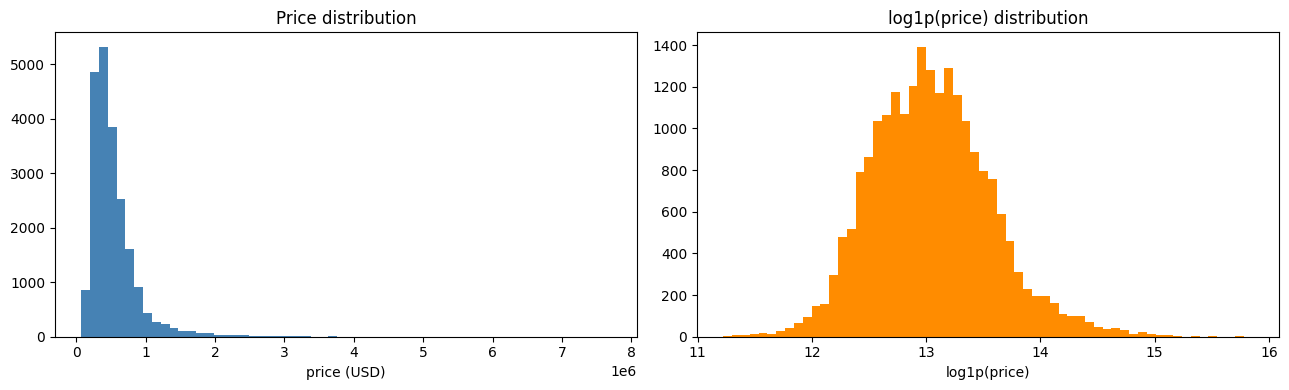

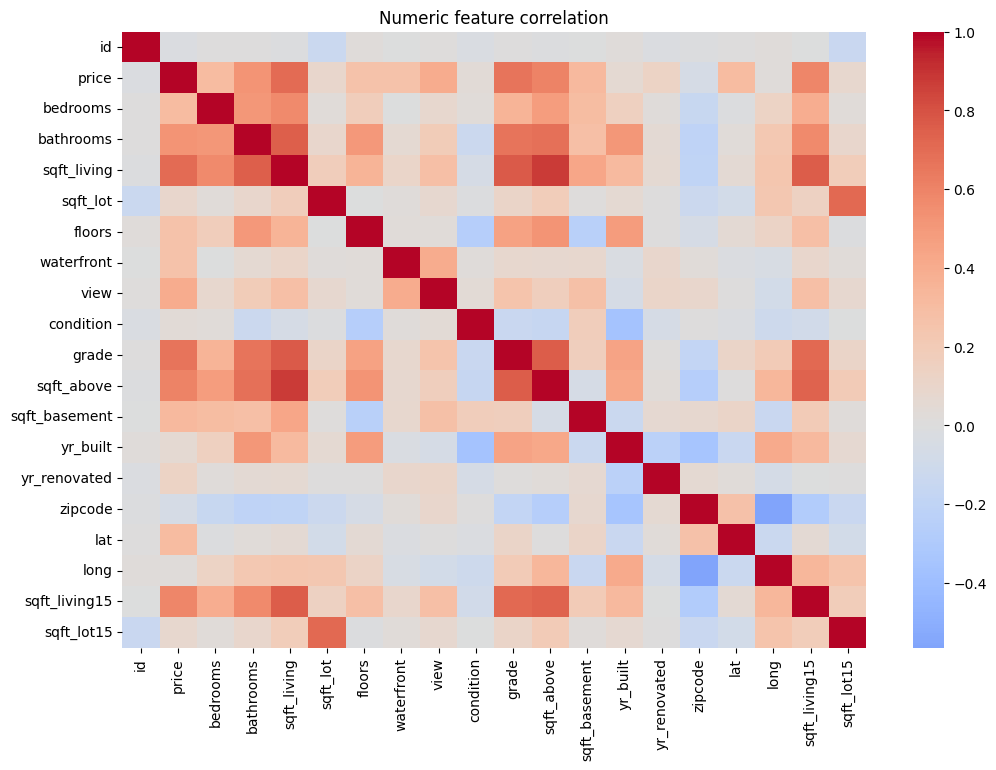

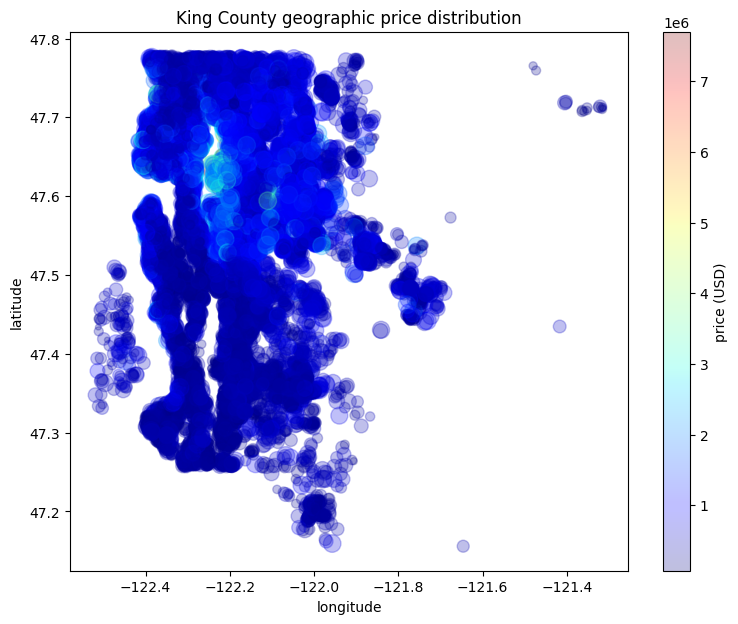

In [3]:
# 价格原始分布和对数分布
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(housing["price"], bins=60, color="steelblue")
axes[0].set_title("Price distribution")
axes[0].set_xlabel("price (USD)")
axes[1].hist(np.log1p(housing["price"]), bins=60, color="darkorange")
axes[1].set_title("log1p(price) distribution")
axes[1].set_xlabel("log1p(price)")
plt.tight_layout()
plt.show()

# 数值变量相关性热图
plt.figure(figsize=(12, 8))
sns.heatmap(housing.select_dtypes(include=np.number).corr(), cmap="coolwarm", center=0)
plt.title("Numeric feature correlation")
plt.show()

# 经纬度、居住面积和价格的空间关系
plt.figure(figsize=(9, 7))
sizes = np.clip(housing["sqft_living"] / 25, 8, 160)
scatter = plt.scatter(
    housing["long"], housing["lat"], s=sizes,
    c=housing["price"], cmap="jet", alpha=0.25
)
plt.colorbar(scatter, label="price (USD)")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.title("King County geographic price distribution")
plt.show()


## 环节 4：训练集与测试集拆分

**这一步在做什么：** 把特征和目标按 80%/20% 随机拆分，并固定随机种子。  
**为什么要做：** 测试集模拟未来未见数据；必须先拆分，再让任何预处理器学习中位数、类别集合或缩放参数，避免数据泄漏。  
**如何被纳入 Pipeline：** 后续所有 Pipeline 都只对 `X_train` 调用 `fit`，对 `X_test` 只调用 `predict` 时的 `transform`。


In [4]:
from sklearn.model_selection import train_test_split

X = housing.drop(columns=["price"]).copy()
y = housing["price"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print(f"训练集：{X_train.shape}，测试集：{X_test.shape}")


训练集：(17290, 20)，测试集：(4323, 20)


## 环节 5：数据清洗

**这一步在做什么：** 确定数值列用中位数填补、类别列用众数填补，并检查异常值处理策略。  
**为什么要做：** 即使当前数据缺失值较少，未来输入仍可能缺失；填补必须在训练折内部学习，不能提前对全量数据计算中位数。  
**如何被纳入 Pipeline：** 环节 7 会分别把 `SimpleImputer(strategy="median")` 和 `SimpleImputer(strategy="most_frequent")` 放入数值、类别子流水线。


In [5]:
# 查看训练集中的缺失值
display(X_train.isna().sum().sort_values(ascending=False).head(10))

# 检查可能影响回归误差的极端值
print("bedrooms 最大值：", X_train["bedrooms"].max())
print("sqft_living 最大值：", X_train["sqft_living"].max())
print("price 最大值：", y_train.max())


id             0
date           0
bedrooms       0
bathrooms      0
sqft_living    0
sqft_lot       0
floors         0
waterfront     0
view           0
condition      0
dtype: int64

bedrooms 最大值： 33
sqft_living 最大值： 12050
price 最大值： 7700000.0


## 环节 6：特征工程

**这一步在做什么：** 实现自定义 `KingCountyFeaturesAdder`，生成每卧室面积、地下室比例、房龄和是否翻修等派生特征。  
**为什么要做：** 比例和时间特征更接近房价形成机制，比单独使用原始面积或年份更有表达力。  
**如何被纳入 Pipeline：** 该类继承 `BaseEstimator` 和 `TransformerMixin`，作为数值子流水线的一步；`fit` 保持标准接口，`transform` 生成新列。


In [6]:
from sklearn.base import BaseEstimator, TransformerMixin


class KingCountyFeaturesAdder(BaseEstimator, TransformerMixin):
    """在数值流水线内部生成 King County 房价的派生特征。"""

    def __init__(self, reference_year=2015):
        self.reference_year = reference_year

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=[
            "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
            "view", "condition", "grade", "sqft_above", "sqft_basement",
            "yr_built", "yr_renovated", "lat", "long",
            "sqft_living15", "sqft_lot15",
        ]).copy()
        X["sqft_per_bedroom"] = X["sqft_living"] / X["bedrooms"].clip(lower=1)
        X["basement_ratio"] = (
            X["sqft_basement"] / X["sqft_living"].replace(0, np.nan)
        )
        X["house_age"] = self.reference_year - X["yr_built"]
        X["is_renovated"] = (X["yr_renovated"] > 0).astype(int)
        return X.replace([np.inf, -np.inf], np.nan)


## 环节 7：数值与类别特征预处理

**这一步在做什么：** 为数值列建立“特征生成 → 缺失值填补 → 标准化”子流水线，为类别列建立“缺失值填补 → One-Hot 编码”子流水线。  
**为什么要做：** 线性模型和岭回归需要统一量纲；邮编和 waterfront 是类别变量，不能直接当成连续数值；未见过的新类别不能让预测报错。  
**如何被纳入 Pipeline：** 两个子流水线会在环节 8 通过 `ColumnTransformer` 合并，所有步骤只在训练集上 `fit`。


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
    "view", "condition", "grade", "sqft_above", "sqft_basement",
    "yr_built", "yr_renovated", "lat", "long",
    "sqft_living15", "sqft_lot15",
]
categorical_features = ["zipcode", "waterfront"]

num_pipeline = Pipeline([
    ("features", KingCountyFeaturesAdder()),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessing = ColumnTransformer([
    ("num", num_pipeline, numeric_features),
    ("cat", cat_pipeline, categorical_features),
])

print(preprocessing)


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('features',
                                                  KingCountyFeaturesAdder()),
                                                 ('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['bedrooms', 'bathrooms', 'sqft_living',
                                  'sqft_lot', 'floors', 'view', 'condition',
                                  'grade', 'sqft_above', 'sqft_basement',
                                  'yr_built', 'yr_renovated', 'lat', 'long',
                                  'sqft_living15', 'sqft_lot15']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                               

## 环节 8：Pipeline 封装

**这一步在做什么：** 检查 `ColumnTransformer` 的数值分支和类别分支，并准备把它与不同回归器串联。  
**为什么要做：** 最终交付物应是一个能够直接接收原始 DataFrame 的单一模型对象，避免手工 `fit_transform` 造成的数据泄漏和复现问题。  
**如何被纳入 Pipeline：** 后续每个模型都采用 `make_pipeline(preprocessing, regressor)`；调参时传入的也是完整 Pipeline。


In [8]:
from sklearn.pipeline import make_pipeline

# 预处理对象将在每个模型 Pipeline 内部独立 fit
print("数值分支：", preprocessing.transformers[0][1])
print("类别分支：", preprocessing.transformers[1][1])


数值分支： Pipeline(steps=[('features', KingCountyFeaturesAdder()),
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])
类别分支： Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])


## 环节 9：至少三类模型训练与比较

**这一步在做什么：** 训练线性回归、岭回归、决策树和随机森林，并比较测试集 RMSE、MAE 和 R²。  
**为什么要做：** 线性模型提供可解释基线，树模型可以表达非线性关系；多个指标能同时观察平均误差、极端误差和解释能力。  
**如何被纳入 Pipeline：** 每个模型都调用自己的 `make_pipeline(preprocessing, estimator)`，训练时传入原始 `X_train`，不能手工传入预处理矩阵。


In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "DecisionTree": DecisionTreeRegressor(
        max_depth=18,
        random_state=RANDOM_STATE,
    ),
    "RandomForest": RandomForestRegressor(
        n_estimators=120,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

fitted_pipelines = {}
model_rows = []

for name, estimator in models.items():
    model_pipeline = make_pipeline(preprocessing, estimator)
    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)
    fitted_pipelines[name] = model_pipeline
    model_rows.append({
        "model": name,
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions),
    })

model_results = pd.DataFrame(model_rows).sort_values("RMSE")
display(model_results)


,model,RMSE,MAE,R2
3,RandomForest,147456.305691,72937.094575,0.856173
0,LinearRegression,169340.049913,98212.629689,0.810314
1,Ridge,170891.512532,98517.996508,0.806823
2,DecisionTree,202235.171163,100464.316173,0.729462


## 环节 10：交叉验证

**这一步在做什么：** 对每一个完整模型 Pipeline 做 3 折交叉验证，计算平均 RMSE 和标准差。  
**为什么要做：** 单次测试集结果可能受随机切分影响，交叉验证可以观察模型稳定性，并为下一步调参提供依据。  
**如何被纳入 Pipeline：** `cross_val_score` 接收的是环节 9 中的完整 Pipeline；每个折会重新拟合预处理步骤和回归器。


In [10]:
from sklearn.model_selection import cross_val_score

cv_rows = []
for name, model_pipeline in fitted_pipelines.items():
    scores = -cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=3,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    cv_rows.append({
        "model": name,
        "CV_RMSE_mean": scores.mean(),
        "CV_RMSE_std": scores.std(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV_RMSE_mean")
display(cv_results)


,model,CV_RMSE_mean,CV_RMSE_std
3,RandomForest,129169.778194,6617.835291
0,LinearRegression,156830.578252,8146.101796
1,Ridge,158075.213125,8920.269854
2,DecisionTree,184283.614690,10720.489902


## 环节 11：GridSearchCV 超参数优化

**这一步在做什么：** 对随机森林 Pipeline 搜索树数量、最大特征比例和叶节点最小样本数。  
**为什么要做：** 合理的超参数可以降低偏差或方差，提升模型泛化能力；网格搜索还能用统一的交叉验证客观比较组合。  
**如何被纳入 Pipeline：** `GridSearchCV` 的第一个参数是完整 `rf_pipeline`，参数名使用双下划线，例如 `randomforestregressor__n_estimators`。


In [11]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = make_pipeline(
    preprocessing,
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
)

param_grid = {
    "randomforestregressor__n_estimators": [80, 160],
    "randomforestregressor__max_features": [0.7, 1.0],
    "randomforestregressor__min_samples_leaf": [1, 2],
}

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)
best_pipeline = grid_search.best_estimator_

print("最佳参数：", grid_search.best_params_)
print("最佳 CV RMSE：", -grid_search.best_score_)


最佳参数： {'randomforestregressor__max_features': 0.7, 'randomforestregressor__min_samples_leaf': 1, 'randomforestregressor__n_estimators': 160}
最佳 CV RMSE： 125911.88705083297


## 环节 12：测试集最终评估

**这一步在做什么：** 使用最优 Pipeline 在完全未参与调参的测试集上计算 RMSE、MAE 和 R²，并绘制预测值与真实值散点图。  
**为什么要做：** 测试集只在最后使用一次，得到对未来数据表现的相对无偏估计；散点图还能显示高价房是否被系统性低估。  
**如何被纳入 Pipeline：** 直接调用 `best_pipeline.predict(X_test)`，由同一个 Pipeline 自动完成全部预处理和预测。


最终测试集 RMSE：148,327 美元
最终测试集 MAE：72,352 美元
最终测试集 R2：0.854


C:\Users\lenovo\AppData\Local\Temp\ipykernel_33632\3536730079.py:21: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_33632\3536730079.py:21: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_33632\3536730079.py:21: UserWarning: Glyph 20215 (\N{CJK UNIFIED IDEOGRAPH-4EF7}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_33632\3536730079.py:21: UserWarning: Glyph 26684 (\N{CJK UNIFIED IDEOGRAPH-683C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_33632\3536730079.py:21: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_33632\3536730079.py:21: UserWarning: Glyph 32

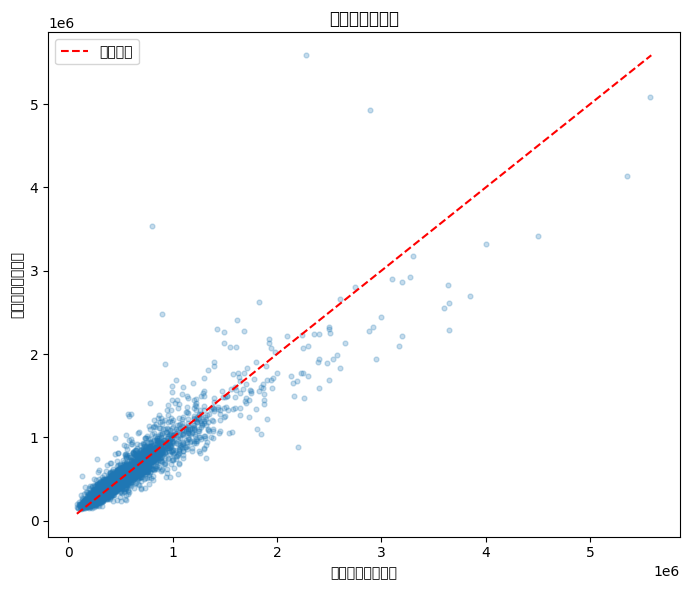

In [12]:
final_predictions = best_pipeline.predict(X_test)
final_rmse = mean_squared_error(y_test, final_predictions) ** 0.5
final_mae = mean_absolute_error(y_test, final_predictions)
final_r2 = r2_score(y_test, final_predictions)

print(f"最终测试集 RMSE：{final_rmse:,.0f} 美元")
print(f"最终测试集 MAE：{final_mae:,.0f} 美元")
print(f"最终测试集 R2：{final_r2:.3f}")

plt.figure(figsize=(7, 6))
plt.scatter(y_test, final_predictions, alpha=0.25, s=12)
limits = [
    min(y_test.min(), final_predictions.min()),
    max(y_test.max(), final_predictions.max()),
]
plt.plot(limits, limits, "r--", label="理想预测")
plt.xlabel("真实价格（美元）")
plt.ylabel("预测价格（美元）")
plt.title("预测值与真实值")
plt.legend()
plt.tight_layout()
plt.show()


## 环节 13：误差分析与可选加分项

**这一步在做什么：** 找出绝对误差最大的样本，分析其房价、面积、等级、邮编、临水属性和地理位置；同时比较对数目标变换。  
**为什么要做：** 评分要求不仅要报告分数，还要解释模型为什么出错。房价右偏时，`log1p` 目标变换可能改善相对误差。  
**如何被纳入 Pipeline：** 误差分析调用已经拟合好的 `best_pipeline`；加分项用 `TransformedTargetRegressor` 包装完整 Pipeline，预测后用 `expm1` 自动还原到美元。


In [13]:
error_table = X_test.copy()
error_table["actual_price"] = y_test
error_table["predicted_price"] = final_predictions
error_table["absolute_error"] = (
    error_table["actual_price"] - error_table["predicted_price"]
).abs()
error_table["relative_error"] = (
    error_table["absolute_error"] / error_table["actual_price"].clip(lower=1)
)

largest_errors = error_table.sort_values(
    "absolute_error", ascending=False
).head(10)
display(largest_errors[[
    "actual_price", "predicted_price", "absolute_error", "relative_error",
    "sqft_living", "grade", "zipcode", "waterfront", "lat", "long",
]])

# 加分项：在完整 Pipeline 外包装目标变换
from sklearn.compose import TransformedTargetRegressor

log_target_model = TransformedTargetRegressor(
    regressor=rf_pipeline,
    func=np.log1p,
    inverse_func=np.expm1,
)
log_target_model.fit(X_train, y_train)
log_predictions = log_target_model.predict(X_test)
log_rmse = mean_squared_error(y_test, log_predictions) ** 0.5
print(f"对数目标变换后的测试集 RMSE：{log_rmse:,.0f} 美元")


,actual_price,predicted_price,absolute_error,relative_error,sqft_living,grade,zipcode,waterfront,lat,long
12777,2280000.0,5.585839e+06,3.305839e+06,1.449930,13540,12,98053,0,47.6675,-121.986
4024,800000.0,3.534315e+06,2.734315e+06,3.417894,7480,11,98166,0,47.4643,-122.368
14556,2888000.0,4.924360e+06,2.036360e+06,0.705111,8670,13,98177,0,47.7295,-122.372
21050,900000.0,2.474462e+06,1.574462e+06,1.749403,7120,12,98006,0,47.5451,-122.114
18482,3650000.0,2.288098e+06,1.361902e+06,0.373124,5020,12,98004,0,47.6146,-122.213
19684,2205000.0,8.788048e+05,1.326195e+06,0.601449,3430,10,98034,0,47.7159,-122.251
1448,5350000.0,4.140963e+06,1.209037e+06,0.225988,8000,12,98004,0,47.6232,-122.220
2085,3850000.0,2.695455e+06,1.154545e+06,0.299882,5770,11,98040,1,47.5850,-122.222
2626,4500000.0,3.421274e+06,1.078726e+06,0.239717,6640,12,98155,1,47.7493,-122.280
13528,3168750.0,2.096998e+06,1.071752e+06,0.338225,4330,12,98004,0,47.6251,-122.218


对数目标变换后的测试集 RMSE：138,631 美元


## 总结反思

与课程中的加州房价案例相比，本项目包含经纬度、邮编、建筑等级和翻修年份，空间与时间信息更丰富；邮编类别更多，不能把它当作连续数值直接输入；King County 价格没有明显封顶现象，高价房会放大 RMSE。最关键的工程经验是把填补、特征生成、编码、缩放和模型训练锁在同一 Pipeline 中：如果提前在全量数据上拟合预处理器，测试集统计量会泄漏到训练过程，交叉验证分数会偏乐观，部署时也容易出现处理不一致。自定义 Transformer 的 `fit` 保持标准接口，`transform` 负责生成面积比例、房龄和翻修特征；对训练时未见过的邮编，OneHotEncoder 会忽略该类别并继续预测。主要误差来自高价、临水、少见地理位置和特殊建筑等级组合。
